In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error,mean_absolute_error,r2_score
from scipy import stats

sns.set_style("whitegrid")
pd.set_option("display.max_columns",50)
pd.set_option("display.float_format","{:.2f}".format)

print("Libraries loaded.")

Libraries loaded.


In [15]:
df= pd.read_csv(r'C:\Users\koura\Downloads\bikes.csv')


In [16]:
df_raw= df

In [17]:
df_raw

,model_name,model_year,kms_driven,owner,location,mileage,power,price
0,Bajaj Avenger Cruise 220 2017,2017,17000 Km,first owner,hyderabad,\n\n 35 kmpl,19 bhp,63500
1,Royal Enfield Classic 350cc 2016,2016,50000 Km,first owner,hyderabad,\n\n 35 kmpl,19.80 bhp,115000
2,Hyosung GT250R 2012,2012,14795 Km,first owner,hyderabad,\n\n 30 kmpl,28 bhp,300000
3,Bajaj Dominar 400 ABS 2017,2017,Mileage 28 Kms,first owner,pondicherry,\n\n 28 Kms,34.50 bhp,100000
4,Jawa Perak 330cc 2020,2020,2000 Km,first owner,bangalore,\n\n,30 bhp,197500
...,...,...,...,...,...,...,...,...
7852,Yamaha YZF-R15 150cc 2011,2011,7000 Km,first owner,agra,\n\n 42 kmpl,16 bhp,55000
7853,Bajaj Discover 100cc 2015,2015,Mileage 80 Kmpl,first owner,delhi,\n\n 80 Kmpl,7.7,28000
7854,Bajaj Pulsar 180cc 2016,2016,6407 Km,first owner,bangalore,\n\n 65 kmpl,17 bhp,61740
7855,Bajaj V15 150cc 2016,2016,7524 Km,first owner,bangalore,\n\n 57 kmpl,11.80 bhp,49000


In [12]:
df['owner'].unique()

<StringArray>
['first owner', 'third owner', 'second owner', 'fourth owner or more']
Length: 4, dtype: str

In [16]:
df.dtypes

model_name      str
model_year    int64
kms_driven      str
owner           str
location        str
mileage         str
power           str
price         int64
dtype: object

In [19]:
df.dtypes

model_name      str
model_year    int64
kms_driven      str
owner           str
location        str
mileage         str
power           str
price         int64
dtype: object

In [20]:
df.duplicated().sum()

np.int64(0)

In [21]:
df.isnull().sum()

model_name     0
model_year     0
kms_driven     0
owner          0
location      19
mileage       11
power         31
price          0
dtype: int64

In [22]:
df['price'].describe()

count      7857.00
mean     106791.34
std      138926.12
min           0.00
25%       42000.00
50%       75000.00
75%      125000.00
max     3000000.00
Name: price, dtype: float64

In [18]:
df.columns

Index(['model_name', 'model_year', 'kms_driven', 'owner', 'location',
       'mileage', 'power', 'price'],
      dtype='str')

In [25]:
df[['kms_driven','mileage','power']]

,kms_driven,mileage,power
0,17000 Km,\n\n 35 kmpl,19 bhp
1,50000 Km,\n\n 35 kmpl,19.80 bhp
2,14795 Km,\n\n 30 kmpl,28 bhp
3,Mileage 28 Kms,\n\n 28 Kms,34.50 bhp
4,2000 Km,\n\n,30 bhp
...,...,...,...
7852,7000 Km,\n\n 42 kmpl,16 bhp
7853,Mileage 80 Kmpl,\n\n 80 Kmpl,7.7
7854,6407 Km,\n\n 65 kmpl,17 bhp
7855,7524 Km,\n\n 57 kmpl,11.80 bhp


In [23]:
def get_number(value):
    if pd.isna(value):
        return np.nan
    value=value.replace(',','')
    number='' #string
    dot_used=False

    for i in value:
        if i.isdigit():
            number+=i
        elif i=='.' and not dot_used:
             dot_used= True
        elif number:
             break
    return float(number) if number else np.nan
    

In [56]:
column_name=['mileage','power','price','model_year','kms_driven']
for i in column_name:
    df_raw[i].apply(get_number)

AttributeError: 'int' object has no attribute 'replace'

In [26]:
df= df.dropna(subset='price')

In [28]:
df[df['price']>0]

,model_name,model_year,kms_driven,owner,location,mileage,power,price
0,Bajaj Avenger Cruise 220 2017,2017,17000 Km,first owner,hyderabad,\n\n 35 kmpl,19 bhp,63500
1,Royal Enfield Classic 350cc 2016,2016,50000 Km,first owner,hyderabad,\n\n 35 kmpl,19.80 bhp,115000
2,Hyosung GT250R 2012,2012,14795 Km,first owner,hyderabad,\n\n 30 kmpl,28 bhp,300000
3,Bajaj Dominar 400 ABS 2017,2017,Mileage 28 Kms,first owner,pondicherry,\n\n 28 Kms,34.50 bhp,100000
4,Jawa Perak 330cc 2020,2020,2000 Km,first owner,bangalore,\n\n,30 bhp,197500
...,...,...,...,...,...,...,...,...
7852,Yamaha YZF-R15 150cc 2011,2011,7000 Km,first owner,agra,\n\n 42 kmpl,16 bhp,55000
7853,Bajaj Discover 100cc 2015,2015,Mileage 80 Kmpl,first owner,delhi,\n\n 80 Kmpl,7.7,28000
7854,Bajaj Pulsar 180cc 2016,2016,6407 Km,first owner,bangalore,\n\n 65 kmpl,17 bhp,61740
7855,Bajaj V15 150cc 2016,2016,7524 Km,first owner,bangalore,\n\n 57 kmpl,11.80 bhp,49000


In [29]:
pd.Timestamp.today().year

2026

In [30]:
df['model_name']

0          Bajaj Avenger Cruise 220 2017
1       Royal Enfield Classic 350cc 2016
2                    Hyosung GT250R 2012
3             Bajaj Dominar 400 ABS 2017
4                  Jawa Perak 330cc 2020
                      ...               
7852           Yamaha YZF-R15 150cc 2011
7853           Bajaj Discover 100cc 2015
7854             Bajaj Pulsar 180cc 2016
7855                Bajaj V15 150cc 2016
7856             Bajaj Pulsar 220cc 2016
Name: model_name, Length: 7857, dtype: str

In [31]:
df[df['model_year']<1990]

,model_name,model_year,kms_driven,owner,location,mileage,power,price
1691,Royal Enfield Bullet 350 cc 1982,1982,22000 Km,first owner,pune,\n\n,NaN,150000
1716,Royal Enfield Bullet 350 cc 1982,1982,16245 Km,first owner,delhi,\n\n,NaN,70000
2211,Bajaj Pulsar NS 200cc 2013,1950,Mileage 35 Kmpl,first owner,noida,\n\n 35 Kmpl,23.19 bhp,55000
2487,Royal Enfield Bullet 350 cc 1982,1982,3000 Km,second owner,lalitpur,\n\n,NaN,130000
2638,Ideal Jawa Yezdi Delux 250 cc 1978,1978,85000 Km,first owner,chikamaglur,\n\n,NaN,100000
2714,Royal Enfield Bullet 350 cc 1982,1982,21000 Km,first owner,nashik,\n\n,NaN,170000
3088,Royal Enfield Bullet 350 cc 1982,1982,10000 Km,first owner,mumbai,\n\n,NaN,60000
3429,Royal Enfield‎ Bullet 350cc 1970,1970,5000 Km,third owner,pune,\n\n 25 kmpl,19.80 bhp,190000
4174,Royal Enfield Standard 350cc 1985,1985,Mileage 40 Kmpl,third owner,kolhapur,\n\n 40 Kmpl,18 bhp,125000
4258,Bajaj Pulsar NS 200cc 2013,1950,Mileage 35 Kmpl,third owner,khalilabad,\n\n 35 Kmpl,23.19 bhp,55000


In [32]:
if 'model_year' in df.columns:
    current_year= pd.Timestamp.today().year
    df['model_year']= df['model_year'].between(1998,current_year)

In [33]:
df

,model_name,model_year,kms_driven,owner,location,mileage,power,price
0,Bajaj Avenger Cruise 220 2017,True,17000 Km,first owner,hyderabad,\n\n 35 kmpl,19 bhp,63500
1,Royal Enfield Classic 350cc 2016,True,50000 Km,first owner,hyderabad,\n\n 35 kmpl,19.80 bhp,115000
2,Hyosung GT250R 2012,True,14795 Km,first owner,hyderabad,\n\n 30 kmpl,28 bhp,300000
3,Bajaj Dominar 400 ABS 2017,True,Mileage 28 Kms,first owner,pondicherry,\n\n 28 Kms,34.50 bhp,100000
4,Jawa Perak 330cc 2020,True,2000 Km,first owner,bangalore,\n\n,30 bhp,197500
...,...,...,...,...,...,...,...,...
7852,Yamaha YZF-R15 150cc 2011,True,7000 Km,first owner,agra,\n\n 42 kmpl,16 bhp,55000
7853,Bajaj Discover 100cc 2015,True,Mileage 80 Kmpl,first owner,delhi,\n\n 80 Kmpl,7.7,28000
7854,Bajaj Pulsar 180cc 2016,True,6407 Km,first owner,bangalore,\n\n 65 kmpl,17 bhp,61740
7855,Bajaj V15 150cc 2016,True,7524 Km,first owner,bangalore,\n\n 57 kmpl,11.80 bhp,49000


In [35]:
if 'model_year' in df.columns:
    current_year = pd.Timestamp.today().year
    df['bike_age'] = current_year - df['model_year']

    if "location" in df.columns:
        df["location"]= df["location"].fillna("unknown")

    print("missing values after basic cleaning:")
    print(df.isnull().sum())

missing values after basic cleaning:
model_name     0
model_year     0
kms_driven     0
owner          0
location       0
mileage       11
power         31
price          0
bike_age       0
dtype: int64


In [36]:
df_clean = df.copy()
df_clean.to_csv("Bikes---------,index=False")
print("Cleaned dataset saved as bikes_cleaned.csv")
display(df_clean.head())

Cleaned dataset saved as bikes_cleaned.csv


,model_name,model_year,kms_driven,owner,location,mileage,power,price,bike_age
0,Bajaj Avenger Cruise 220 2017,True,17000 Km,first owner,hyderabad,\n\n 35 kmpl,19 bhp,63500,2025
1,Royal Enfield Classic 350cc 2016,True,50000 Km,first owner,hyderabad,\n\n 35 kmpl,19.80 bhp,115000,2025
2,Hyosung GT250R 2012,True,14795 Km,first owner,hyderabad,\n\n 30 kmpl,28 bhp,300000,2025
3,Bajaj Dominar 400 ABS 2017,True,Mileage 28 Kms,first owner,pondicherry,\n\n 28 Kms,34.50 bhp,100000,2025
4,Jawa Perak 330cc 2020,True,2000 Km,first owner,bangalore,\n\n,30 bhp,197500,2025


In [37]:
df_clean['price'].describe()


count      7857.00
mean     106791.34
std      138926.12
min           0.00
25%       42000.00
50%       75000.00
75%      125000.00
max     3000000.00
Name: price, dtype: float64

In [38]:
df_clean['price'].skew()

np.float64(6.212031912939482)

<Axes: xlabel='price', ylabel='Count'>

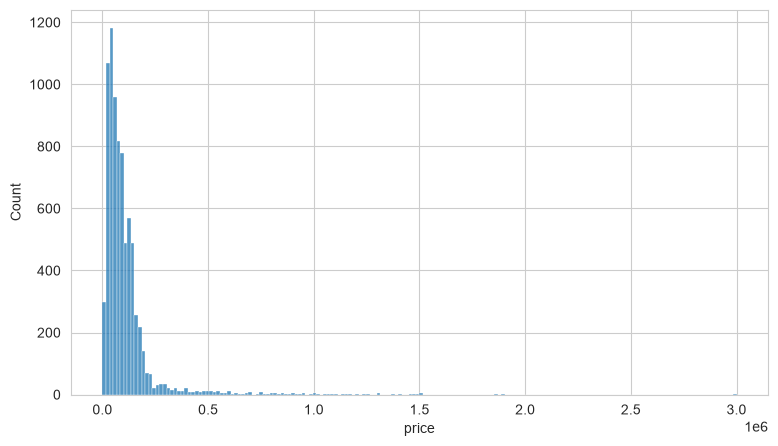

In [42]:
plt.figure(figsize=(9,5))
sns.histplot(data=df_clean,x='price')

<Axes: xlabel='price'>

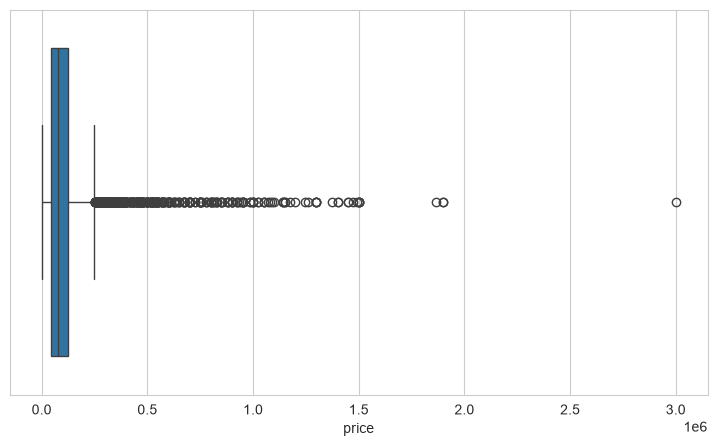

In [57]:
plt.figure(figsize=(9,5))
sns.boxplot(data=df_clean,x='price')

In [44]:
df_clean['model_name'].str.split()

0          [Bajaj, Avenger, Cruise, 220, 2017]
1       [Royal, Enfield, Classic, 350cc, 2016]
2                      [Hyosung, GT250R, 2012]
3             [Bajaj, Dominar, 400, ABS, 2017]
4                   [Jawa, Perak, 330cc, 2020]
                         ...                  
7852            [Yamaha, YZF-R15, 150cc, 2011]
7853            [Bajaj, Discover, 100cc, 2015]
7854              [Bajaj, Pulsar, 180cc, 2016]
7855                 [Bajaj, V15, 150cc, 2016]
7856              [Bajaj, Pulsar, 220cc, 2016]
Name: model_name, Length: 7857, dtype: object

In [45]:
df_clean['brand']=df_clean['model_name'].str.split().str[0]

In [46]:
df_clean['brand'].unique()

array(['Bajaj', 'Royal', 'Hyosung', 'Jawa', 'KTM', 'TVS', 'Yamaha',
       'Honda', 'UM', 'Hero', 'Suzuki', 'Husqvarna', 'Mahindra',
       'Harley-Davidson', 'Kawasaki', 'Benelli', 'Triumph', 'Ducati',
       'BMW', 'Ideal', 'BenelliImperiale', 'Moto', 'Fb', 'Indian',
       'Yazdi', 'Aprilia', 'MV', 'yamaha'], dtype=object)

In [47]:
df_clean['brand']=df_clean['model_name'].str.split().str[0].str.lower()

In [50]:
df_clean.groupby('brand')['price'].agg(['median','mean','count'])

,median,mean,count
brand,,,
aprilia,1000000.00,1000000.00,2
bajaj,50000.00,56963.17,2105
benelli,260000.00,301581.89,53
benelliimperiale,213750.00,216910.33,6
bmw,274800.00,397860.00,10
ducati,907293.50,976293.69,16
fb,320850.00,320850.00,2
harley-davidson,450000.00,512722.60,171
hero,33000.00,38198.98,808


In [62]:
brand_stats=df_clean.groupby('brand')['price'].agg(['median','mean','count']).reset_index

In [63]:
brand_stats

<bound method DataFrame.reset_index of                      median       mean  count
brand                                        
aprilia          1000000.00 1000000.00      2
bajaj              50000.00   56963.17   2105
benelli           260000.00  301581.89     53
benelliimperiale  213750.00  216910.33      6
bmw               274800.00  397860.00     10
ducati            907293.50  976293.69     16
fb                320850.00  320850.00      2
harley-davidson   450000.00  512722.60    171
hero               33000.00   38198.98    808
honda              49749.50   70906.22    530
husqvarna         205000.00  206767.00     11
hyosung           193600.00  213450.56     54
ideal             100000.00  100000.00      1
indian           1900000.00 1900000.00      1
jawa              165000.00  171286.13     46
kawasaki          465000.00  496517.70     67
ktm               147000.00  150354.56    491
mahindra           33000.00   63588.85     27
moto             1866057.00 1866057.00   

In [75]:
brand_stats[brand_stats['count']>0].sort_value(by='median',ascending=False)

TypeError: 'method' object is not subscriptable

In [76]:
plt.figure(figsize=(12,7))
sns.barplot(data=brand_top_10, x='brand',y='median',color='red')

NameError: name 'brand_top_10' is not defined

<Figure size 1200x700 with 0 Axes>

In [77]:
df_clean[['kms_driven','price']].corr()

ValueError: could not convert string to float: '17000 Km'

In [71]:
plot_data= df_clean.dropna(subset=['kms_driven','price'])

In [73]:
plot_data= df_clean.dropna[subset]=['kms_driven','price']
if len(plot_data)>3000:
    plot_data = plot_data.sample(3000, random_stats=42)

plt.figure(figsize=(10,4))

sns.scatterplot(data= plot_data, x='kms_driven', y='price', color= 'red')

NameError: name 'subset' is not defined